# Lab 01 - Sentiment Analysis Using Traditional Machine Learning
Dataset: UCI Sentiment Labelled Sentences (Amazon, IMDB, Yelp)

## Task 1: Download and load the dataset

In [17]:
!wget -q "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip" -O sentiment.zip
!unzip -q -o sentiment.zip
!ls "sentiment labelled sentences"

amazon_cells_labelled.txt  imdb_labelled.txt  readme.txt  yelp_labelled.txt


In [18]:
import pandas as pd

files = {
    "amazon": "sentiment labelled sentences/amazon_cells_labelled.txt",
    "imdb":   "sentiment labelled sentences/imdb_labelled.txt",
    "yelp":   "sentiment labelled sentences/yelp_labelled.txt",
}

frames = []
for source, path in files.items():
    df_part = pd.read_csv(path, sep="\t", header=None, names=["text", "label"])
    df_part["source"] = source
    frames.append(df_part)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
print(df["label"].value_counts())
df.head(10)


(2748, 3)
label
1    1386
0    1362
Name: count, dtype: int64


,text,label,source
0,So there is no way for me to plug it in here in the US u...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more than 45 m...,0,amazon
4,The mic is great.,1,amazon
5,I have to jiggle the plug to get it to line up right to ...,0,amazon
6,"If you have several dozen or several hundred contacts, t...",0,amazon
7,If you are Razr owner...you must have this!,1,amazon
8,"Needless to say, I wasted my money.",0,amazon
9,What a waste of money and time!.,0,amazon


## Task 2: Text preprocessing
Steps: lowercase, remove punctuation and special characters, remove extra whitespace, create a clean_text column.


In [19]:
import re

def clean_text(text):
    text = text.lower()                    # convert to lowercase
    text = text.replace("'", "")           # don't -> dont (keeps negations as one word)
    text = re.sub(r"[^a-z\s]", " ", text)  # remove punctuation, numbers, special characters
    text = re.sub(r"\s+", " ", text)       # collapse extra whitespace
    return text.strip()

df["clean_text"] = df["text"].apply(clean_text)

# Compare original and preprocessed text
pd.set_option("display.max_colwidth", 80)
df[["text", "clean_text"]].head(10)

,text,clean_text
0,So there is no way for me to plug it in here in the US unless I go by a conv...,so there is no way for me to plug it in here in the us unless i go by a conv...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than minutes major problems
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up right to get decent volume.,i have to jiggle the plug to get it to line up right to get decent volume
6,"If you have several dozen or several hundred contacts, then imagine the fun ...",if you have several dozen or several hundred contacts then imagine the fun o...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


In [20]:
df["len_original"] = df["text"].apply(lambda x: len(x.split()))
df["len_clean"] = df["clean_text"].apply(lambda x: len(x.split()))
print("Average words per sentence (original):", round(df["len_original"].mean(), 2))
print("Average words per sentence (clean):   ", round(df["len_clean"].mean(), 2))

Average words per sentence (original): 13.01
Average words per sentence (clean):    12.9


## Task 3: Explore the text data
Positive and negative examples, frequent words, and differences between the two classes.

In [21]:
print("POSITIVE examples:")
for t in df[df["label"] == 1]["text"].sample(5, random_state=42):
    print("  -", t)

print("\nNEGATIVE examples:")
for t in df[df["label"] == 0]["text"].sample(5, random_state=42):
    print("  -", t)

POSITIVE examples:
  - The original Body and Soul (1947) is a masterpiece.  
  - Better than you'd expect.
  - So we went to Tigerlilly and had a fantastic afternoon!
  - Lovely little thriller from Hitchcock, with lots of nice shenanigans surrounding a murdered spy, a kidnapped child, a nasty church, a foreign plot and some random taxidermists.  
  - Conclusion - I loved it.  

NEGATIVE examples:
  - That's a huge design flaw (unless I'm not using it correctly, which I don't think is the case).
  - However, my recent experience at this particular location was not so good.
  - The ambiance here did not feel like a buffet setting, but more of a douchey indoor garden for tea and biscuits.
  - The acting was bad, the dialogs were extremely shallow and insincere.  
  - There was hardly any meat.


In [22]:
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

stop_words = set(stopwords.words("english"))

def top_words(series, n=15, remove_stop=True):
    words = " ".join(series).split()
    if remove_stop:
        words = [w for w in words if w not in stop_words]
    return Counter(words).most_common(n)

print("Top 15 words overall (filler words kept):")
print(top_words(df["clean_text"], remove_stop=False))

Top 15 words overall (filler words kept):
[('the', 1953), ('and', 1138), ('i', 901), ('a', 891), ('is', 754), ('it', 674), ('to', 670), ('this', 643), ('of', 624), ('was', 571), ('in', 400), ('for', 336), ('not', 306), ('that', 304), ('with', 274)]


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


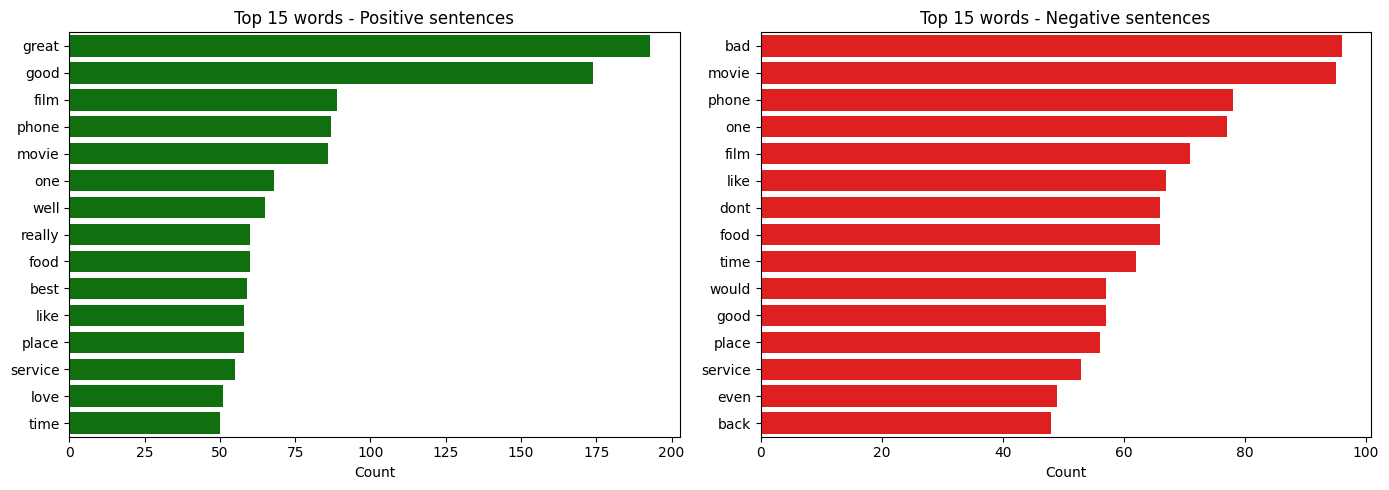

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lab, name, color) in zip(axes, [(1, "Positive", "green"), (0, "Negative", "red")]):
    data = top_words(df[df["label"] == lab]["clean_text"])
    words, counts = zip(*data)
    sns.barplot(x=list(counts), y=list(words), ax=ax, color=color)
    ax.set_title(f"Top 15 words - {name} sentences")
    ax.set_xlabel("Count")
plt.tight_layout()
plt.show()

## Task 4: Split the dataset
80% training, 20% testing.

## Task 5: Bag-of-Words representation

In [24]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape[0], "sentences")
print("Test set:    ", X_test.shape[0], "sentences")
print("\nTraining label distribution:\n", y_train.value_counts())
print("\nTest label distribution:\n", y_test.value_counts())

Training set: 2198 sentences
Test set:     550 sentences

Training label distribution:
 label
1    1109
0    1089
Name: count, dtype: int64

Test label distribution:
 label
1    277
0    273
Name: count, dtype: int64


In [25]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(X_train)   # learn vocabulary from TRAINING data only
X_test_bow = vectorizer.transform(X_test)         # apply the same vocabulary to test data

print("Training matrix shape:", X_train_bow.shape)
print("Test matrix shape:    ", X_test_bow.shape)
print("Vocabulary size:      ", len(vectorizer.get_feature_names_out()))

Training matrix shape: (2198, 4475)
Test matrix shape:     (550, 4475)
Vocabulary size:       4475


In [26]:
sample = X_train.iloc[0]
print("Sentence:", sample)
vec = vectorizer.transform([sample]).toarray()[0]
words = vectorizer.get_feature_names_out()
print({w: int(c) for w, c in zip(words, vec) if c > 0})

Sentence: i do not know if this was emilio estevezs directorial debut but the pacing the interplay and development of the characters as well as some clever camera work surrounding the character estevez plays all suggest a natural eye
{'all': 1, 'and': 1, 'as': 2, 'but': 1, 'camera': 1, 'character': 1, 'characters': 1, 'clever': 1, 'debut': 1, 'development': 1, 'directorial': 1, 'do': 1, 'emilio': 1, 'estevez': 1, 'estevezs': 1, 'eye': 1, 'if': 1, 'interplay': 1, 'know': 1, 'natural': 1, 'not': 1, 'of': 1, 'pacing': 1, 'plays': 1, 'some': 1, 'suggest': 1, 'surrounding': 1, 'the': 4, 'this': 1, 'was': 1, 'well': 1, 'work': 1}


## Task 6: Train ML models
Logistic Regression and Linear SVM on BOW features.

## Task 7: Evaluate model performance
Accuracy, Precision, Recall, F1-score, confusion matrix.

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_bow, y_train)

svm = LinearSVC()
svm.fit(X_train_bow, y_train)

print("Both models trained.")

Both models trained.


In [28]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

models = {"Logistic Regression": lr, "Linear SVM": svm}
rows = []
for name, model in models.items():
    pred = model.predict(X_test_bow)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(rows).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8127,0.8271,0.7942,0.8103
1,Linear SVM,0.8145,0.8253,0.8014,0.8132


In [29]:
for name, model in models.items():
    pred = model.predict(X_test_bow)
    print("=" * 55)
    print(name)
    print(classification_report(y_test, pred, target_names=["Negative (0)", "Positive (1)"]))

Logistic Regression
              precision    recall  f1-score   support

Negative (0)       0.80      0.83      0.82       273
Positive (1)       0.83      0.79      0.81       277

    accuracy                           0.81       550
   macro avg       0.81      0.81      0.81       550
weighted avg       0.81      0.81      0.81       550

Linear SVM
              precision    recall  f1-score   support

Negative (0)       0.80      0.83      0.82       273
Positive (1)       0.83      0.80      0.81       277

    accuracy                           0.81       550
   macro avg       0.81      0.81      0.81       550
weighted avg       0.81      0.81      0.81       550



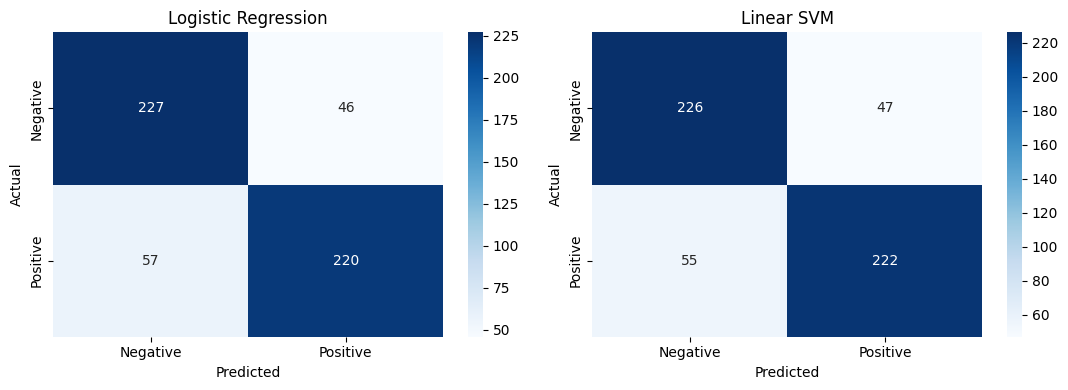

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_bow))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Negative", "Positive"],
                yticklabels=["Negative", "Positive"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## Task 8: Test the model with new sentences

In [31]:
def predict_sentiment(sentence):
    cleaned = clean_text(sentence)
    vec = vectorizer.transform([cleaned])
    lr_pred = lr.predict(vec)[0]
    lr_prob = lr.predict_proba(vec)[0][lr_pred]
    svm_pred = svm.predict(vec)[0]
    label = {1: "Positive", 0: "Negative"}
    return label[lr_pred], round(lr_prob, 2), label[svm_pred]

new_sentences = [
    "I absolutely love this phone, the battery is great",
    "This was a terrible waste of money",
    "The food was delicious and the staff were friendly",
    "The movie was boring and way too long",
    "The service was not bad at all",
    "I did not like this place",
    "Great, another delay. Just what I needed.",
    "The product arrived on Tuesday",
]

test_df = pd.DataFrame(
    [(s, *predict_sentiment(s)) for s in new_sentences],
    columns=["Sentence", "LogReg prediction", "LogReg confidence", "SVM prediction"]
)
pd.set_option("display.max_colwidth", 60)
test_df

,Sentence,LogReg prediction,LogReg confidence,SVM prediction
0,"I absolutely love this phone, the battery is great",Positive,0.99,Positive
1,This was a terrible waste of money,Negative,0.99,Negative
2,The food was delicious and the staff were friendly,Positive,0.94,Positive
3,The movie was boring and way too long,Negative,0.69,Negative
4,The service was not bad at all,Negative,1.00,Negative
5,I did not like this place,Negative,0.83,Negative
6,"Great, another delay. Just what I needed.",Positive,0.85,Positive
7,The product arrived on Tuesday,Negative,0.61,Negative
